# 02 · Ön İşleme ve Veri Bölme

01 defterindeki EDA'da verilen kararları bütün veriye uyguluyoruz, sonra veriyi eğitim / doğrulama / test kümelerine bölüyoruz:

| Karar | Kanıt (01) |
|---|---|
| Kanallar: **DBZ + VEL + WIDTH** | D3 |
| **En alçak tarama** (0,5°) | D4 |
| **Son zaman adımı** | D5 |
| Sabit ölçekleme aralıkları (WIDTH 0–16) | D2 |
| `uint8` ile saklama | D6 |
| Boş pikselleri doldurma | D1 |

1. Bölüm ön işlemenin ne yaptığını tek bir örnekte gösteriyor. 2. Bölüm seçilen yılların hepsini işleyip Google Drive'a kaydediyor. 3. Bölüm veriyi kümelere bölüp bölmenin doğru olduğunu kontrol ediyor.

**Colab'da CPU çalışma zamanıyla çalıştır** (GPU gerekmez).

In [1]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import os, sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} pull -q
    %pip install -q h5netcdf h5py
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(REPO))
print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab | repo: /content/tornado-cnn


In [2]:
import shutil
import numpy as np
import matplotlib.pyplot as plt
from src import paths, tornet, viz

cfg = paths.load_config()
print("ayarlar:", cfg)

ayarlar: {'years': [2015, 2017, 2019], 'variables': ['DBZ', 'VEL', 'WIDTH'], 'sweep': 0, 'frame': -1, 'drive_subdir': 'tornado-cnn'}


## 1. Ön işleme ne yapıyor? (tek örnekte gösterim)

Bütün veriye uygulamadan önce bir örnekte görelim ve kontrol edelim. Adımlar (`src/tornet.py`):

1. **Seçme:** DBZ, VEL ve WIDTH; en alçak tarama; son zaman adımı → boyut `(3, 120, 240)`.
2. **Ölçekleme:** Her kanal sabit bir fiziksel aralıkla [-1, 1]'e çevrilir (DBZ −20…60 dBZ, VEL −60…60 m/s, WIDTH 0…16 m/s). Kanallar farklı aralıklarda olursa ağ birine daha fazla önem verebilir ve öğrenme zorlaşır. Aralıklar sabit olduğu için test kümesinden bilgi sızmaz.
3. **Sıkıştırma:** Değerler 1–255 arası tam sayı (`uint8`) olarak saklanır; `0` boş pikseller için ayrılmıştır. Veri 4 kat küçülür.
4. **Boşlukları doldurma** (yüklerken): DBZ → −1 (yankı yok), VEL → 0 (hareket yok), WIDTH → −1 (türbülans yok).

In [3]:
one = tornet.sample_from_tar(tornet.tar_url(2017), per_category={"TOR": 1})
ds = next(iter(one.values()))

q = tornet.preprocess_sample(ds, cfg["variables"], cfg["sweep"], cfg["frame"])   # saklanan hal
x = tornet.from_uint8(q, cfg["variables"])                                     # ağın girdisi
print("saklanan:", q.shape, q.dtype, "| ağın girdisi:", x.shape, x.dtype, f"[{x.min():.2f}, {x.max():.2f}]")
print("kanal başına boş piksel (%):", {v: round(float(p), 1) for v, p in zip(cfg["variables"], 100 * (q == 0).mean(axis=(1, 2)))})

saklanan: (3, 120, 240) uint8 | ağın girdisi: (3, 120, 240) float32 [-1.00, 0.87]
kanal başına boş piksel (%): {'DBZ': 18.4, 'VEL': 31.8, 'WIDTH': 31.8}


**Yuvarlama kontrolü:** Saklanan değeri fiziksel birime geri çevirip ham değerle karşılaştırıyoruz. Hata, 01'deki D6'da hesapladığımız en büyük yuvarlama hatasını geçmemeli.

In [4]:
for i, v in enumerate(cfg["variables"]):
    lo, hi = tornet.CHANNEL_RANGES[v]
    raw = ds[v].values[cfg["frame"], :, :, cfg["sweep"]]
    ok = np.isfinite(raw)
    back = (x[i][ok] + 1) / 2 * (hi - lo) + lo           # [-1, 1] -> fiziksel birim
    err = np.abs(np.clip(raw[ok], lo, hi) - back).max()
    print(f"{v:6s} en büyük hata: {err:.3f}  (sınır: {(hi - lo) / 254 / 2:.3f})")

DBZ    en büyük hata: 0.157  (sınır: 0.157)
VEL    en büyük hata: 0.228  (sınır: 0.236)
WIDTH  en büyük hata: 0.031  (sınır: 0.031)


**Ağın gördüğü görüntü.** Satırlar açı (0,5°'lik 120 hücre), sütunlar mesafe (250 m'lik 240 hücre). 01'deki haritaya göre şekiller gerilmiş görünür: yelpaze dilimi düz bir dikdörtgene açılmış gibi. Haritaya çevirmek pikseller arasında tahmin (enterpolasyon) gerektirir ve bilgi kaybettirir; bu yüzden ağa bu haliyle veriyoruz.

VEL'deki beyaz alanların bir kısmı gerçekten durgun hava, bir kısmı ölçüm olmayan yerler (0 ile doldurduk). D1'deki boş piksel oranlarını hatırla.

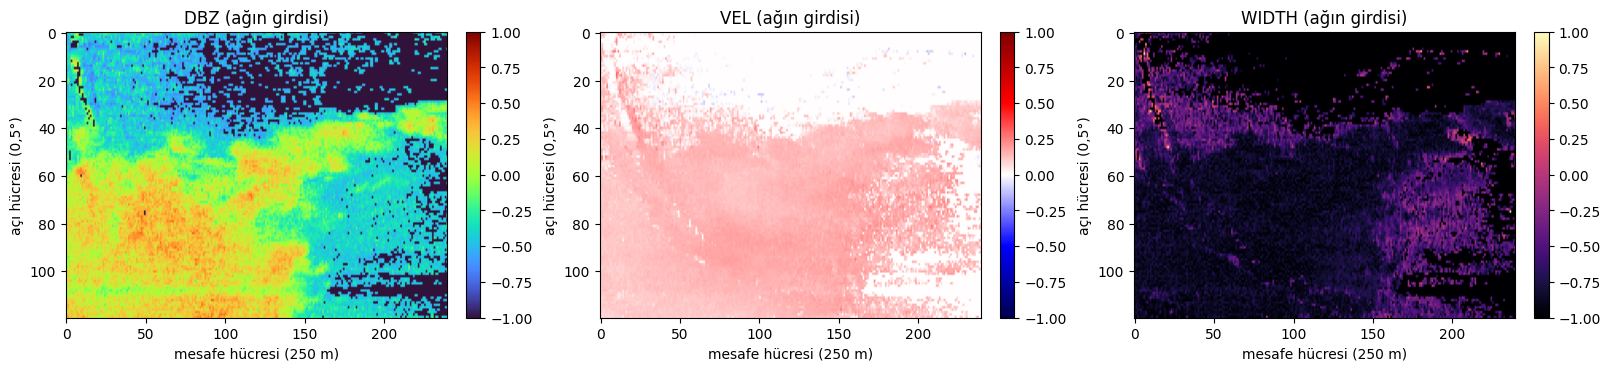

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), layout="constrained")
for ax, v, img in zip(axes, cfg["variables"], x):
    m = ax.imshow(img, aspect="auto", cmap=viz.CMAPS[v], vmin=-1, vmax=1)
    ax.set_title(f"{v} (ağın girdisi)")
    ax.set_xlabel("mesafe hücresi (250 m)")
    ax.set_ylabel("açı hücresi (0,5°)")
    plt.colorbar(m, ax=ax)
plt.show()

## 2. Seçilen yılların hepsini işleme

`configs/data.json` dosyasındaki her yıl için:

1. arşiv Zenodo'dan Colab diskine indirilir (15–18 GB, geçici),
2. her örnek **arşiv açılmadan** okunur ve yukarıdaki ön işleme uygulanır,
3. `tornet_<yıl>.npz` Google Drive'a kaydedilir (yıl başına ~1,5–2 GB),
4. arşiv silinir.

Süre çoğunlukla Zenodo'nun indirme hızına bağlı: toplam ~51 GB, yaklaşık 30 dakika ile 2 saat arası.

* **İndirme sırasında hücrede yazı akmayabilir.** İlerlemeyi sağ üstteki **Disk** göstergesinden izle: indirme sürdükçe dolar.
* Zenodo büyük dosyalarda bağlantıyı arada kesebilir. Kod bu durumda **kaldığı yerden devam ederek** tekrar dener ve ekrana "bağlantı kesildi... devam ediliyor" yazar; bir şey yapmana gerek yok.
* Colab oturumu koparsa defteri tekrar çalıştır: bitmiş yıllar atlanır, yarım kalan indirme kaldığı yerden devam eder.

Google Drive'da yaklaşık **6–7 GB** boş yer gerekir.

In [6]:
SCRATCH = paths.scratch_dir()      # geçici, büyük
OUT = paths.processed_dir()        # kalıcı (Colab'da Drive)

def free_gb(p):
    return shutil.disk_usage(p).free / 1e9

print("yıllar:", cfg["years"], "| kanallar:", cfg["variables"])
print(f"geçici klasör: {SCRATCH}  ({free_gb(SCRATCH):.0f} GB boş)")
print(f"çıktı klasörü: {OUT}  ({free_gb(OUT):.0f} GB boş)")

yıllar: [2015, 2017, 2019] | kanallar: ['DBZ', 'VEL', 'WIDTH']
geçici klasör: /content/tornet_raw  (110 GB boş)
çıktı klasörü: /content/drive/MyDrive/tornado-cnn/data/processed  (104 GB boş)


In [7]:
acat = tornet.get_catalog(paths.data_dir())

for year in cfg["years"]:
    out_file = OUT / f"tornet_{year}.npz"
    if out_file.exists():
        print(f"{year}: zaten tamamlanmış")
        continue
    tar_path = SCRATCH / f"tornet_{year}.tar.gz"
    size = tornet.remote_size(year, tar_path.name)           # indirmenin tamamlandığını kontrol etmek için
    print(f"{year}: indiriliyor ({size / 1e9:.1f} GB) ..." if size else f"{year}: indiriliyor ...")
    tornet.download(tornet.tar_url(year), tar_path, expected_size=size)
    print(f"{year}: işleniyor ...")
    tornet.process_year(year, tar_path, OUT, cfg["variables"], cfg["sweep"], cfg["frame"], catalog=cat)
    tar_path.unlink()               # sonraki yıl için Colab diskinde yer aç
    print(f"{year}: arşiv silindi, geçici klasörde {free_gb(SCRATCH):.0f} GB boş")

2015: indiriliyor (17.4 GB) ...
  indirme tamam: 17.40 GB
2015: işleniyor ...


TorNet 2015:   0%|          | 0/23623 [00:00<?, ?dosya/s]

Kaydedildi: /content/drive/MyDrive/tornado-cnn/data/processed/tornet_2015.npz | 23623 örnek, 1754 hortum | 0.81 GB
2015: arşiv silindi, geçici klasörde 115 GB boş
2017: indiriliyor (15.1 GB) ...
  indirme tamam: 15.12 GB
2017: işleniyor ...


TorNet 2017:   0%|          | 0/20072 [00:00<?, ?dosya/s]

Kaydedildi: /content/drive/MyDrive/tornado-cnn/data/processed/tornet_2017.npz | 20072 örnek, 1623 hortum | 0.72 GB
2017: arşiv silindi, geçici klasörde 114 GB boş
2019: indiriliyor (18.2 GB) ...
  indirme tamam: 18.22 GB
2019: işleniyor ...


TorNet 2019:   0%|          | 0/24619 [00:00<?, ?dosya/s]

Kaydedildi: /content/drive/MyDrive/tornado-cnn/data/processed/tornet_2019.npz | 24619 örnek, 2011 hortum | 0.87 GB
2019: arşiv silindi, geçici klasörde 113 GB boş


## Sonuçları katalogla karşılaştır

In [8]:
for year in cfg["years"]:
    d = np.load(OUT / f"tornet_{year}.npz")
    X, y, names = d["X"], d["y"], d["filename"]
    expected = cat[cat["year"] == year]
    match = cat.set_index("filename").loc[names, "label"].to_numpy()
    print(f"{year}: X {X.shape} {X.dtype} | kanallar {list(d['variables'])} | {len(y):,} örnek (katalog {len(expected):,}) | "
          f"{int(y.sum()):,} hortum | etiketler katalogla aynı: {(match == y).all()}")

2015: X (23623, 3, 120, 240) uint8 | kanallar [np.str_('DBZ'), np.str_('VEL'), np.str_('WIDTH')] | 23,623 örnek (katalog 23,623) | 1,754 hortum | etiketler katalogla aynı: True
2017: X (20072, 3, 120, 240) uint8 | kanallar [np.str_('DBZ'), np.str_('VEL'), np.str_('WIDTH')] | 20,072 örnek (katalog 20,072) | 1,623 hortum | etiketler katalogla aynı: True
2019: X (24619, 3, 120, 240) uint8 | kanallar [np.str_('DBZ'), np.str_('VEL'), np.str_('WIDTH')] | 24,619 örnek (katalog 24,619) | 2,011 hortum | etiketler katalogla aynı: True


## 3. Eğitim / doğrulama / test bölmesi

| Küme | Nereden? | Ne için? |
|---|---|---|
| **Test** | Veri setinin hazır `test` kısmı (MIT'nin ayrımı) | Rapordaki son sonuç. En sona kadar **hiç kullanılmaz.** |
| **Doğrulama** | `train` kısmından, **fırtına olayına göre** ayrılan ~%15 | Eğitimi izlemek: ezber başladı mı (early stopping), en iyi tur hangisi, karar eşiği ne olmalı |
| **Eğitim** | `train` kısmının geri kalanı | Modelin öğrendiği veri |
| *(çıkarılan)* | Test kümesindeki bir fırtınaya ait `train` örnekleri | Sızıntıyı önlemek için kullanılmaz |

**Fırtına olayı (`episode_id`) nedir?** ABD Ulusal Hava Servisi, aynı hava sistemine bağlı olayları (hortumlar, uyarılar) tek bir "olay" altında gruplar. Bir fırtına olayı birkaç saat sürebilir ve içinde birden fazla hortum ya da uyarı olabilir; TorNet'te aynı olaydan birçok örnek alınmıştır.

**Neden fırtınaya göre?** Aynı fırtınanın birkaç dakika arayla alınmış örnekleri birbirine çok benzer. Biri eğitimde, diğeri doğrulamada olursa model doğrulamada daha önce gördüğü fırtınayla karşılaşır ve başarı olduğundan yüksek görünür (5. hafta, "fotoğraf kopyaları" örneği). Bu yüzden bir fırtınanın bütün örnekleri tek bir kümeye gider.

Bölme aynı ayarla her çalıştırmada aynı çıkar (`seed=42`) ve doğrulamada hortum oranı eğitimdekine yakın olacak şekilde yapılır. Kod: `src/data.py`.

In [9]:
from src import data

splits = data.make_splits(cat, cfg["years"], val_fraction=0.15, seed=42)
data.split_summary(splits)

,örnek,hortum,hortum_%,fırtına (episode)
split,,,,
train,49138,3865,7.9,2935
val,8040,690,8.6,490
test,11078,797,7.2,603
dropped,58,36,62.1,7


### Bölme kontrolleri

Her satır bir kontrol. Hepsinde **✅** görünmeli.

In [10]:
data.check_splits(splits, cat, cfg["years"])

,sonuç,beklenen,tamam
kontrol,,,
Eğitim ile doğrulamada ortak fırtına,0,0,✅
Eğitim ile testte ortak fırtına,0,0,✅
Doğrulama ile testte ortak fırtına,0,0,✅
Eğitim + doğrulamada kalan 'ortak' fırtına,0,0,✅
Toplam örnek (eğitim + doğrulama + çıkarılan + test),68314,68314,✅
Test örneği,11078,11078,✅
Testteki hortum,797,797,✅
Test kümesi hazır test kümesiyle aynı dosyalar mı?,True,True,✅
Etiketler kategoriyle uyumlu mu? (TOR = 1),True,True,✅


Yıllara göre dağılım ve işlenmiş dosyalarla eşleşme: Bölmedeki her dosya, 2. bölümde kaydedilen `.npz` dosyalarında bulunmalı.

In [11]:
print(splits.groupby(["split", "year"]).size().unstack())

processed_names = set()
for year in cfg["years"]:
    f = OUT / f"tornet_{year}.npz"
    if f.exists():
        processed_names |= set(np.load(f)["filename"])
if processed_names:
    missing = set(splits["filename"]) - processed_names
    print(f"\nİşlenmiş dosyalarda bulunmayan örnek: {len(missing)}  (beklenen: 0)")
else:
    print("\nİşlenmiş dosyalar henüz yok; bu kontrol 2. bölüm bitince yapılabilir.")

year      2015   2017   2019
split                       
dropped     30     14     14
test      3902   3145   4031
train    17165  14311  17662
val       2526   2602   2912

İşlenmiş dosyalarda bulunmayan örnek: 0  (beklenen: 0)


Bölme Drive'a küçük bir tablo olarak kaydediliyor (hangi dosya hangi kümede). Sonraki defterler bu tabloyu okuyacak; böylece herkes aynı bölmeyi kullanır.

In [12]:
split_file = paths.data_dir() / "splits.csv"
splits.to_csv(split_file, index=False)
print("kaydedildi:", split_file, f"({len(splits):,} satır)")

kaydedildi: /content/drive/MyDrive/tornado-cnn/data/splits.csv (68,314 satır)
